In [161]:
# Import Essential Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from datetime import timedelta
from pandas.plotting import register_matplotlib_converters
from statsmodels.tsa.statespace.sarimax import SARIMAX
register_matplotlib_converters()
from time import time

# Prepare Bicycle Dataset
Use dtheday as the date and cnt as total daily rentals. One row is one day across the recorded system; cnt is not the number of unique people or bikes needed at a station.
- Parse and sort dates.
- Check for duplicate dates.
- Check for missing calendar days.
- Check for missing count values.
- Check for negative or non-integer counts.

Record each findings. The unmodified daily file should contain 731 dates from January 1 2011 to December 31 2012. **If checks fails fail, do not invent observations or silently delete dates.** Use only the dated ctn series as the SARIMA input. Other fields, including casual, registered, and measured weather, are not model inputs. You do not need to create lag_1 or lag_7 feature columns; SARIMA handles its own time dependence.

> Inspecting the dataset.

In [162]:
# The program below loads data from day.csv. It parses the date to be in day/month/Year format. Sort the data dteday.
# Marking the the dteday as the index column unlocks pandas' built in time-series-engine,
# which makes queries and plotting easier.
bike_shares = pd.read_csv("../data/raw/day.csv", index_col="dteday")
bike_shares.index = pd.to_datetime(bike_shares.index, format="%Y-%m-%d")
bike_shares = bike_shares.sort_index()
print(bike_shares.head())
print(bike_shares.tail())
print(bike_shares.dtypes)
print(bike_shares.index.dtype)

            instant  season  yr  mnth  holiday  weekday  workingday  \
dteday                                                                
2011-01-01        1       1   0     1        0        6           0   
2011-01-02        2       1   0     1        0        0           0   
2011-01-03        3       1   0     1        0        1           1   
2011-01-04        4       1   0     1        0        2           1   
2011-01-05        5       1   0     1        0        3           1   

            weathersit      temp     atemp       hum  windspeed  casual  \
dteday                                                                    
2011-01-01           2  0.344167  0.363625  0.805833   0.160446     331   
2011-01-02           2  0.363478  0.353739  0.696087   0.248539     131   
2011-01-03           1  0.196364  0.189405  0.437273   0.248309     120   
2011-01-04           1  0.200000  0.212122  0.590435   0.160296     108   
2011-01-05           1  0.226957  0.229270  0.436957

In [163]:
# Checking for duplicate dates.
assert bike_shares.index.duplicated().sum() == 0, "Data set contains duplicated dates."
if bike_shares.index.duplicated().sum() > 0:
    print(bike_shares[bike_shares.index.duplicated()])
else:
    print("No duplicate dates found.")

# Check for missing calendar days.
#January 1 2011 to December 31 2012
start_date = datetime(2011, 1, 1)
end_date = datetime(2012, 12, 31)
missing_dates = pd.date_range(start=start_date, end=end_date).difference(pd.to_datetime(bike_shares.index))
assert len(missing_dates) == 0, "Data set contains missing dates."
if len(missing_dates) > 0:
    print(missing_dates)
else:
    print("No missing dates found")

# Check for missing count values.
assert bike_shares.cnt.isna().sum() == 0, "Data set contains missing value."
if bike_shares.cnt.isna().sum() > 0:
    print(bike_shares[bike_shares.cnt.isna()])
else:
    print("No missing count values found")

# Check for negative or non-integer counts
# First, converts all ctn records to numeric (e.g. int64 or float64).
# It ensures that strings are converted to proper numerical data types
# and non numerical data is converted into NaN.
invalid_mask =  (bike_shares.cnt < 0) | ((bike_shares.cnt % 1) != 0)
assert not invalid_mask.any(), "Data set contains negative or non-integer values"
if invalid_mask.any():
    print(bike_shares[invalid_mask])
else:
    print("No negative or non-integer values found.")

No duplicate dates found.
No missing dates found
No missing count values found
No negative or non-integer values found.


In [164]:
print(bike_shares.index.value_counts().sum())

731


Based on the outputs, the bike_shares data set is clean. It does not contain:
- any duplicated dates, 
- missing dates, 
- missing daily rental records, and 
- invalid daily rental records.

It is also confirmed that the dataset contains exactly 731 records.

# Separate Past Evidence From Future Prediction

In [165]:
# Training dataset
training_start_date = datetime(2011,1,1)
training_end_date = datetime(2012,12,17)
training_set = bike_shares.loc[training_start_date.strftime("%Y-%m-%d"):training_end_date.strftime("%Y-%m-%d")]["cnt"]
print(training_set.head())
print(training_set.tail())



dteday
2011-01-01     985
2011-01-02     801
2011-01-03    1349
2011-01-04    1562
2011-01-05    1600
Name: cnt, dtype: int64
dteday
2012-12-13    5532
2012-12-14    5611
2012-12-15    5047
2012-12-16    3786
2012-12-17    4585
Name: cnt, dtype: int64


In [166]:
# Testing Dataset
test_start_date = datetime(2012,12,18)
test_end_date = datetime(2012,12,31)
test_set = bike_shares.loc[test_start_date.strftime("%Y-%m-%d"):test_end_date.strftime("%Y-%m-%d")]["cnt"]
print(test_set.head())
print(test_set.tail())

dteday
2012-12-18    5557
2012-12-19    5267
2012-12-20    4128
2012-12-21    3623
2012-12-22    1749
Name: cnt, dtype: int64
dteday
2012-12-27    2114
2012-12-28    3095
2012-12-29    1341
2012-12-30    1796
2012-12-31    2729
Name: cnt, dtype: int64


> I expect daily rentals to show a weekly pattern because demands changes throughout the week. During weekdays, demands for bike rentals increased because of daily commuters (e.g. workers, students). Meanwhile, demands on the weekends decreases because daily commuters decreases and the focus shifts from commuting to leisure riding. As a result, there is a distinct difference between Monday-Friday and Saturday-Sunday rental volumes.

KeyError: 'cnt'

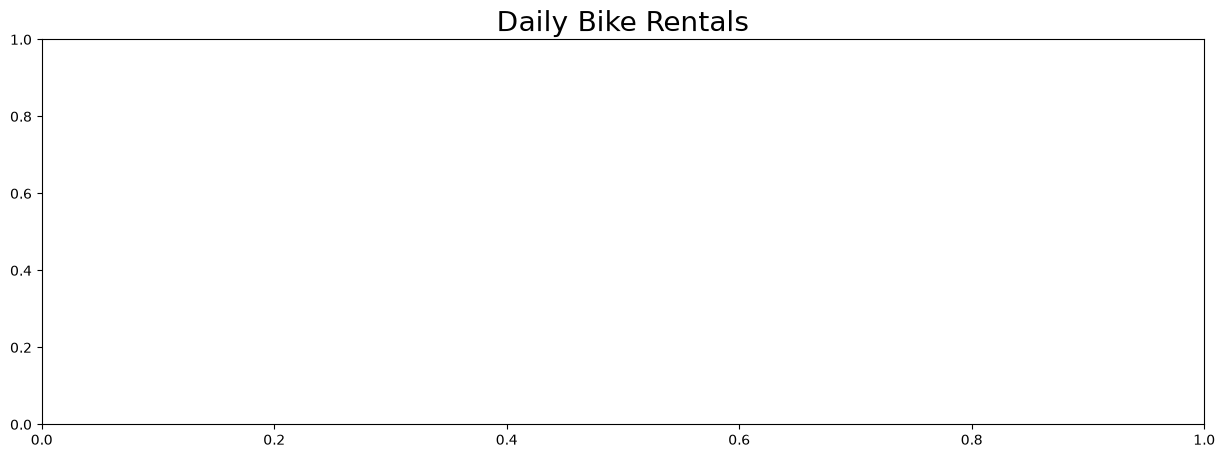

In [167]:

plt.figure(figsize=(15,5))
plt.title("Daily Bike Rentals", fontdict={"size": 20})
training_set["cnt"].plot()
plt.xlabel("Date", fontdict={"size": 20})
plt.ylabel("Rentals", fontdict={"size": 20})

for year in range(start_date.year-1, end_date.year+1):
    plt.axvline(pd.to_datetime(str(year)+'-01-01'), color='k', linestyle='--', alpha=0.2) 

In [ ]:
training_set.index.dtype
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekly_summary = (
    training_set.groupby(training_set.index.day_name())["cnt"]
    .agg(mean_rentals="mean", sample_size="count")
    .reindex(days_order)
)

print("Unsorted Weekly Summary")
print(weekly_summary)

KeyError: 'Column not found: cnt'

In [ ]:
max_mean = weekly_summary.loc[weekly_summary['mean_rentals'].idxmax()]
min_mean = weekly_summary.loc[weekly_summary['mean_rentals'].idxmin()]

print("Highest Training Mean")
print(max_mean)
print("\nLowest Training Mean")
print(min_mean)
print("\nDifference")
print(max_mean.mean_rentals - min_mean.mean_rentals)
print((max_mean.mean_rentals - min_mean.mean_rentals) / max_mean.mean_rentals * 100)

Highest Training Mean
mean_rentals    4716.392157
sample_size      102.000000
Name: Friday, dtype: float64

Lowest Training Mean
mean_rentals    4276.15534
sample_size      103.00000
Name: Sunday, dtype: float64

Difference
440.2368170569198
9.334186013695627


**Which day of the week has the highest mean?**
- Friday, with an average of 4716.39 rental volumes

**which day of the week has the lowest mean?**
- Sunday, with an average of 4276.15 rental volumes

**Give both means and their difference.**
- `Difference=440.24`

**Does these support your expectation of weekly pattern? Explain that weekdays means alone do not prove a stable seven-day cycle or explain its cause.**
Base on the means alone, 